In [1]:
import pandas as pd

train = pd.read_csv("train.csv")
test = pd.read_csv("test_tweets.csv")

print("Training Data:")
display(train.head())

print("Testing Data:")
display(test.head())

Training Data:


,id,label,tweet
0,1,0,@user when a father is dysfunctional and is s...
1,2,0,@user @user thanks for #lyft credit i can't us...
2,3,0,bihday your majesty
3,4,0,#model i love u take with u all the time in ...
4,5,0,factsguide: society now #motivation


Testing Data:


,id,tweet
0,31963,#studiolife #aislife #requires #passion #dedic...
1,31964,@user #white #supremacists want everyone to s...
2,31965,safe ways to heal your #acne!! #altwaystohe...
3,31966,is the hp and the cursed child book up for res...
4,31967,"3rd #bihday to my amazing, hilarious #nephew..."


In [2]:
print("Training shape:", train.shape)
print("Testing shape:", test.shape)

print("\nColumn names:")
print(train.columns.tolist())

print("\nMissing values:")
print(train.isnull().sum())

print("\nLabel distribution:")
print(train["label"].value_counts())

Training shape: (31962, 3)
Testing shape: (17197, 2)

Column names:
['id', 'label', 'tweet']

Missing values:
id       0
label    0
tweet    0
dtype: int64

Label distribution:
label
0    29720
1     2242
Name: count, dtype: int64


In [3]:
# Display random tweets from the training dataset

print("Random tweets from the dataset:")

display(train[['tweet', 'label']].sample(10, random_state=42))

Random tweets from the dataset:


,tweet,label
12227,@user âmy mom says my smile is captivatingâ...,0
14709,"in 3 days i will be meeting my sis-n-law, coun...",0
19319,hating the conservative homophobes using this ...,0
4308,awee if this doesn't #scream #friday #acewe...,0
24055,fathersday #fatherÃ¢ÂÂs #day #god! #ÃÂ« #...,0
2275,grooving fuuuunn nightâ¨â¨â¨ #bangkok #las...,0
22304,a very #koala bear,0
15297,treat people the way you want to be treated. #...,0
21896,and now for the final roundup. tissues ready ...,0
29841,@user our global media platform would very muc...,0


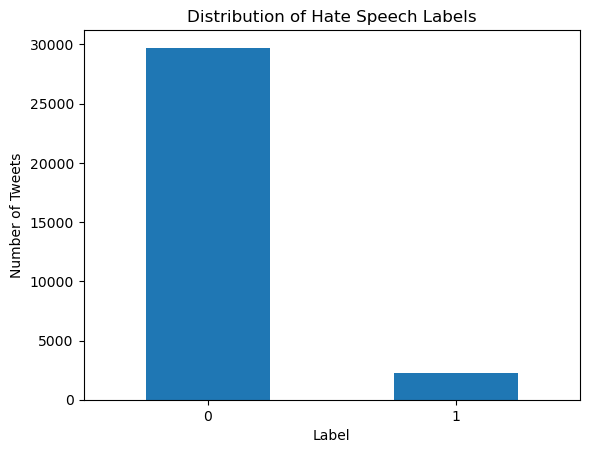

In [4]:
import matplotlib.pyplot as plt

# Count each class
label_counts = train['label'].value_counts().sort_index()

# Plot the distribution
label_counts.plot(kind='bar')

plt.title('Distribution of Hate Speech Labels')
plt.xlabel('Label')
plt.ylabel('Number of Tweets')
plt.xticks(rotation=0)

plt.show()

In [5]:
import re

def clean_tweet(text):
    # Convert text to lowercase
    text = str(text).lower()

    # Replace URLs
    text = re.sub(r'https?://\S+|www\.\S+', ' URL ', text)

    # Replace usernames
    text = re.sub(r'@\w+', ' USER ', text)

    # Keep hashtag words and remove the # symbol
    text = re.sub(r'#(\w+)', r'\1', text)

    # Remove the retweet marker
    text = re.sub(r'\brt\b', ' ', text)

    # Normalize spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [6]:
example = "@Ahmed RT I LOVE Python!!! #MachineLearning https://example.com"

print("Before:")
print(example)

print("\nAfter:")
print(clean_tweet(example))

Before:
@Ahmed RT I LOVE Python!!! #MachineLearning https://example.com

After:
USER i love python!!! machinelearning URL


In [7]:
from sklearn.model_selection import train_test_split

X = train['tweet'].fillna('').astype(str)
y = train['label']

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_valid))

Training samples: 25569
Validation samples: 6393


In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    preprocessor=clean_tweet,
    lowercase=False,
    ngram_range=(1, 2),
    min_df=2,
    max_features=50000,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_valid_tfidf = tfidf.transform(X_valid)

print("Training matrix shape:", X_train_tfidf.shape)
print("Validation matrix shape:", X_valid_tfidf.shape)

Training matrix shape: (25569, 42422)
Validation matrix shape: (6393, 42422)


In [9]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

model.fit(X_train_tfidf, y_train)

print("Model training completed!")

Model training completed!


In [10]:
from sklearn.metrics import (
    f1_score,
    classification_report,
    confusion_matrix
)

# Predict labels for validation data
y_pred = model.predict(X_valid_tfidf)

# Calculate F1-score for class 1
f1 = f1_score(y_valid, y_pred, pos_label=1)

print("F1-Score:", round(f1, 4))

print("\nClassification Report:")
print(classification_report(y_valid, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_valid, y_pred))

F1-Score: 0.6503

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.95      0.97      5945
           1       0.55      0.80      0.65       448

    accuracy                           0.94      6393
   macro avg       0.77      0.87      0.81      6393
weighted avg       0.95      0.94      0.94      6393


Confusion Matrix:
[[5652  293]
 [  91  357]]


In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import FeatureUnion
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, classification_report

# Word-level TF-IDF
word_tfidf = TfidfVectorizer(
    preprocessor=clean_tweet,
    lowercase=False,
    ngram_range=(1, 2),
    min_df=2,
    max_features=50000,
    sublinear_tf=True
)

# Character-level TF-IDF
char_tfidf = TfidfVectorizer(
    preprocessor=clean_tweet,
    lowercase=False,
    analyzer='char',
    ngram_range=(3, 5),
    min_df=2,
    max_features=50000,
    sublinear_tf=True
)

# Combine word and character features
combined_tfidf = FeatureUnion([
    ('word', word_tfidf),
    ('char', char_tfidf)
])

# Learn features from training data only
X_train_combined = combined_tfidf.fit_transform(X_train)

# Transform validation data using the same learned features
X_valid_combined = combined_tfidf.transform(X_valid)

print("Training shape:", X_train_combined.shape)
print("Validation shape:", X_valid_combined.shape)

Training shape: (25569, 92422)
Validation shape: (6393, 92422)


In [12]:
improved_model = LogisticRegression(
    max_iter=1500,
    class_weight='balanced',
    C=2.0,
    random_state=42
)

improved_model.fit(X_train_combined, y_train)

# Predict validation labels
improved_predictions = improved_model.predict(X_valid_combined)

# Evaluate F1-score
improved_f1 = f1_score(
    y_valid,
    improved_predictions,
    pos_label=1
)

print("Old F1-Score:", 0.6503)
print("New F1-Score:", round(improved_f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_valid,
        improved_predictions,
        zero_division=0
    )
)

Old F1-Score: 0.6503
New F1-Score: 0.7245

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.97      0.98      5945
           1       0.67      0.78      0.72       448

    accuracy                           0.96      6393
   macro avg       0.83      0.88      0.85      6393
weighted avg       0.96      0.96      0.96      6393



In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

for c in [0.5, 1.0, 2.0, 3.0, 5.0]:
    model_test = LogisticRegression(
        max_iter=1500,
        class_weight='balanced',
        C=c,
        random_state=42
    )

    model_test.fit(X_train_combined, y_train)

    predictions = model_test.predict(X_valid_combined)

    score = f1_score(y_valid, predictions, pos_label=1)

    print(f"C = {c}, F1-Score = {score:.4f}")

C = 0.5, F1-Score = 0.6741
C = 1.0, F1-Score = 0.7068
C = 2.0, F1-Score = 0.7245
C = 3.0, F1-Score = 0.7269
C = 5.0, F1-Score = 0.7328


In [14]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import FeatureUnion
from sklearn.linear_model import LogisticRegression

# 1. Load the datasets
train = pd.read_csv("train.csv")
test = pd.read_csv("test_tweets.csv")

# 2. Separate training data
X_train = train["tweet"].fillna("").astype(str)
y_train = train["label"]

X_test = test["tweet"].fillna("").astype(str)

# 3. Create Word TF-IDF
word_tfidf = TfidfVectorizer(
    preprocessor=clean_tweet,
    lowercase=False,
    ngram_range=(1, 2),
    min_df=2,
    max_features=50000,
    sublinear_tf=True
)

# 4. Create Character TF-IDF
char_tfidf = TfidfVectorizer(
    preprocessor=clean_tweet,
    lowercase=False,
    analyzer="char",
    ngram_range=(3, 5),
    min_df=2,
    max_features=50000,
    sublinear_tf=True
)

# 5. Combine both vectorizers
combined_tfidf = FeatureUnion([
    ("word", word_tfidf),
    ("char", char_tfidf)
])

# 6. Fit TF-IDF on all training tweets
X_train_combined = combined_tfidf.fit_transform(X_train)

# 7. Transform test tweets
X_test_combined = combined_tfidf.transform(X_test)

# 8. Train the final model
final_model = LogisticRegression(
    max_iter=1500,
    class_weight="balanced",
    C=5.0,
    random_state=42
)

final_model.fit(X_train_combined, y_train)

# 9. Predict labels for test tweets
test_predictions = final_model.predict(X_test_combined)

# 10. Save predictions
submission = pd.DataFrame({
    "label": test_predictions
})

submission.to_csv(
    "test_predictions.csv",
    index=False,
    header=False
)

print("File created successfully!")
print("Number of predictions:", len(test_predictions))
print("Expected number:", len(test))
print("Predicted classes:")
print(pd.Series(test_predictions).value_counts().sort_index())

File created successfully!
Number of predictions: 17197
Expected number: 17197
Predicted classes:
0    15799
1     1398
Name: count, dtype: int64
